# HW1　二維捲積（2D Convolution）

**組員：**

| 學號 | 姓名 |
|:-:|:-:|
| 12370601 | 曾楷程 |
| 12370503 | 周韋辰 |
| 12370370 | 賴冠廷 |

**作業目標：** 使用二維捲積處理一張自己選擇的影像，透過實際結果判斷濾波器的作用，並提出一個有意義的應用。

---
## 一　三種 Kernel

依題目以 H1、H2、H3 稱呼，**不預先假設其用途**，功能留到「三」由實際結果判斷。

| H1 = 1/9 × | H2 = | H3 = |
|:-:|:-:|:-:|
| `[ 1  1  1 ]`<br>`[ 1  1  1 ]`<br>`[ 1  1  1 ]` | `[ 0 -1  0 ]`<br>`[-1  4 -1 ]`<br>`[ 0 -1  0 ]` | `[ 0 -1  0 ]`<br>`[-1  5 -1 ]`<br>`[ 0 -1  0 ]` |

下方程式定義三個 Kernel，並自行實作 2D 捲積函式 `conv2d`（kernel 翻轉 180° 後逐點相乘相加，邊界採 reflect 補值，輸出保留浮點數、不先截斷）。

In [1]:
# 一、三種 Kernel 與 2D 捲積函式
import os
import urllib.request
import numpy as np
import matplotlib.pyplot as plt
import cv2

H1 = np.ones((3, 3), dtype=np.float64) / 9.0
H2 = np.array([[ 0, -1,  0],
               [-1,  4, -1],
               [ 0, -1,  0]], dtype=np.float64)
H3 = np.array([[ 0, -1,  0],
               [-1,  5, -1],
               [ 0, -1,  0]], dtype=np.float64)
KERNELS = {"H1": H1, "H2": H2, "H3": H3}

def conv2d(img, kernel):
    # 2D 捲積：y[m,n] = Σ_i Σ_j h[i,j] · x[m-i, n-j]
    # 作法：kernel 翻轉 180° 後，把 9 個位移後的影像加權相加（等同滑動視窗逐點計算，但用陣列運算較快）
    k = np.flipud(np.fliplr(kernel))
    kh, kw = k.shape
    ph, pw = kh // 2, kw // 2
    padded = np.pad(img.astype(np.float64), ((ph, ph), (pw, pw)), mode="reflect")
    out = np.zeros(img.shape, dtype=np.float64)
    for i in range(kh):
        for j in range(kw):
            out += k[i, j] * padded[i:i + img.shape[0], j:j + img.shape[1]]
    return out   # 保留原始浮點結果（可能有負值或 > 255）

for name, H in KERNELS.items():
    print(f"{name} =\n{np.round(H, 3)}\n係數總和 = {H.sum():.3f}\n")


H1 =
[[0.111 0.111 0.111]
 [0.111 0.111 0.111]
 [0.111 0.111 0.111]]
係數總和 = 1.000

H2 =
[[ 0. -1.  0.]
 [-1.  4. -1.]
 [ 0. -1.  0.]]
係數總和 = 0.000

H3 =
[[ 0. -1.  0.]
 [-1.  5. -1.]
 [ 0. -1.  0.]]
係數總和 = 1.000



---
## 二　實際操作

### 1　自選影像

- **影像來源：** 從網路取得，Wikimedia Commons 的台北 101 照片〈Taipei 101 2009 amk.jpg〉（CC 授權）。
  網址：https://commons.wikimedia.org/wiki/File:Taipei_101_2009_amk.jpg
- **想觀察／改善的問題：** 照片中有三種很不一樣的區域：大片**平滑的天空**、帶有**明顯直線輪廓與窗格**的大樓，以及**紋理雜亂的樹叢**。
  想觀察三個 Kernel 對這三種區域的影響有何不同，並嘗試**自動找出大樓的建築邊線**（輪廓與每一節的分界）。
- 為了運算速度，長邊縮小到 800 像素。

原始尺寸： (2040, 1280)  → 縮小後： (800, 502)


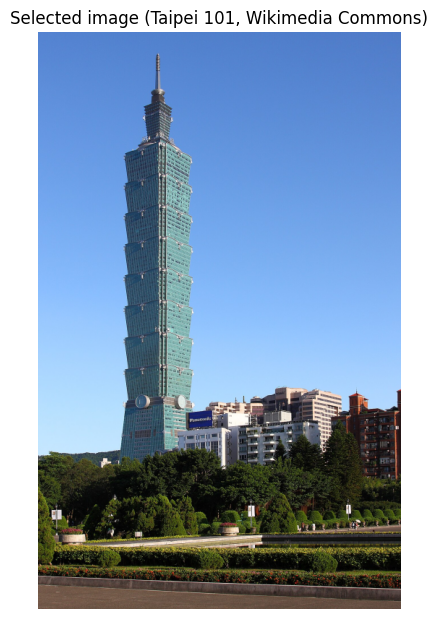

In [2]:
# 二-1 自選影像：從網路下載
IMG_URL  = "https://commons.wikimedia.org/wiki/Special:FilePath/Taipei_101_2009_amk.jpg?width=1000"
IMG_PATH = "/content/taipei101.jpg"
if not os.path.exists(IMG_PATH):
    req = urllib.request.Request(IMG_URL, headers={"User-Agent": "Mozilla/5.0 (Colab HW1 2D convolution)"})
    with urllib.request.urlopen(req, timeout=30) as r, open(IMG_PATH, "wb") as f:
        f.write(r.read())

rgb = cv2.cvtColor(cv2.imread(IMG_PATH), cv2.COLOR_BGR2RGB)
h, w = rgb.shape[:2]
s = 800 / max(h, w)
if s < 1:
    rgb = cv2.resize(rgb, (round(w * s), round(h * s)), interpolation=cv2.INTER_AREA)
print("原始尺寸：", (h, w), " → 縮小後：", rgb.shape[:2])

plt.figure(figsize=(5, 7.5))
plt.imshow(rgb); plt.title("Selected image (Taipei 101, Wikimedia Commons)"); plt.axis("off")
plt.show()


### 2　使用三個 Kernel

先把彩色照片轉為**灰階**，再將 H1、H2、H3 分別套用在**同一張灰階影像**上，保留原圖與三種輸出（`out1`、`out2`、`out3`，皆為未截斷的浮點數）。
另外用 OpenCV 的 `cv2.filter2D` 計算同樣的結果，確認自寫的 `conv2d` 正確。

In [3]:
# 二-2 轉灰階，套用 H1、H2、H3
gray = cv2.cvtColor(rgb, cv2.COLOR_RGB2GRAY).astype(np.float64)
print("灰階影像尺寸：", gray.shape, "，值域：", gray.min(), "~", gray.max())

out1 = conv2d(gray, H1)
out2 = conv2d(gray, H2)
out3 = conv2d(gray, H3)
outs = {"H1": out1, "H2": out2, "H3": out3}

print("\n輸出的實際數值範圍（尚未做任何顯示處理）：")
for name, out in outs.items():
    ref = cv2.filter2D(gray, cv2.CV_64F, np.flipud(np.fliplr(KERNELS[name])), borderType=cv2.BORDER_REFLECT_101)
    n_low, n_high = (out < 0).mean() * 100, (out > 255).mean() * 100
    print(f"  {name}: 最小 {out.min():8.2f}，最大 {out.max():8.2f}；"
          f"<0 的像素 {n_low:5.1f}%，>255 的像素 {n_high:5.1f}%；與 OpenCV 最大誤差 {np.abs(out - ref).max():.1e}")


灰階影像尺寸： (800, 502) ，值域： 1.0 ~ 254.0

輸出的實際數值範圍（尚未做任何顯示處理）：
  H1: 最小     1.78，最大   253.00；<0 的像素   0.0%，>255 的像素   0.0%；與 OpenCV 最大誤差 0.0e+00
  H2: 最小  -466.00，最大   579.00；<0 的像素  45.7%，>255 的像素   0.2%；與 OpenCV 最大誤差 0.0e+00
  H3: 最小  -418.00，最大   829.00；<0 的像素   9.0%，>255 的像素   2.5%；與 OpenCV 最大誤差 0.0e+00


### 3　比較結果

由上一格的數值範圍可知，輸出不一定落在 0～255，直接轉成 `uint8` 顯示會造成溢位（例如 −10 變成 246）而誤判效果，因此分別處理：

| 輸出 | 實際範圍的特性 | 顯示方式 |
|:-:|---|---|
| H1 | 全部落在 0～255 內 | 不需縮放，直接顯示 |
| H2 | 約一半像素為**負值**，平均約為 0 | **取絕對值** \|x\|，再以第 99 百分位對應到 255 線性縮放（超過者截斷為 255）。不用最大值縮放，是因為少數極端值會讓整張圖變得太暗 |
| H3 | 少部分像素 < 0 或 > 255 | **截斷**到 0～255 |

四張影像並排如下，第二列為大樓中段的局部放大。

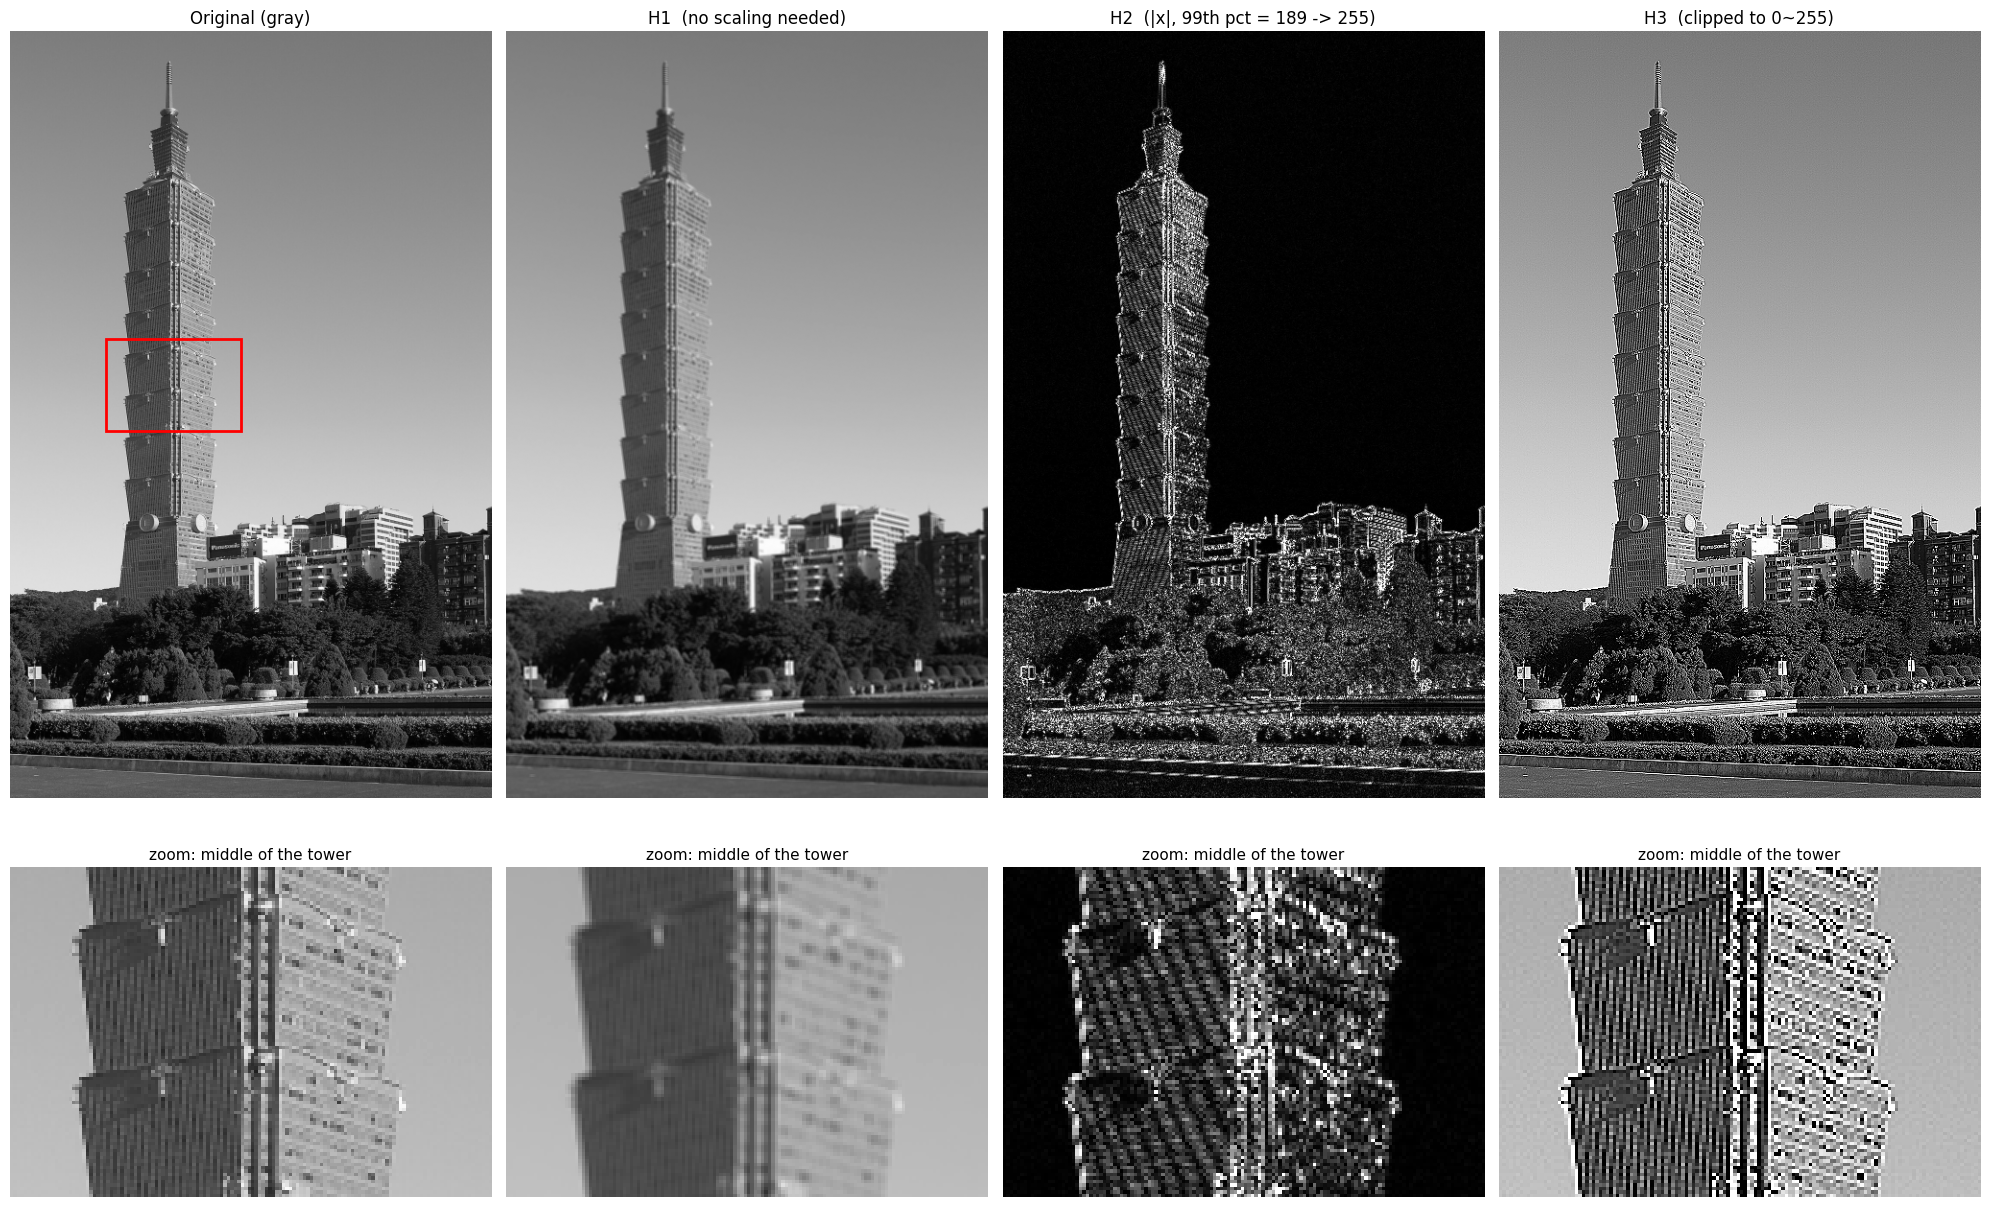

In [4]:
# 二-3 四張影像並排比較
def show_clip(x):                 # 截斷到 0~255
    return np.clip(x, 0, 255).astype(np.uint8)

def show_abs_scaled(x, pct=99):   # 取絕對值，第 pct 百分位對應 255
    a = np.abs(x)
    return np.clip(255 * a / np.percentile(a, pct), 0, 255).astype(np.uint8)

disp = [gray.astype(np.uint8), show_clip(out1), show_abs_scaled(out2), show_clip(out3)]
titles = ["Original (gray)",
          "H1  (no scaling needed)",
          f"H2  (|x|, 99th pct = {np.percentile(np.abs(out2), 99):.0f} -> 255)",
          "H3  (clipped to 0~255)"]

H_, W_ = gray.shape
zoom = (slice(int(0.40 * H_), int(0.52 * H_)), slice(int(0.20 * W_), int(0.48 * W_)))   # 大樓中段

fig, axes = plt.subplots(2, 4, figsize=(20, 13), gridspec_kw={"height_ratios": [3, 1.2]})
for k, (im, t) in enumerate(zip(disp, titles)):
    axes[0, k].imshow(im, cmap="gray", vmin=0, vmax=255); axes[0, k].set_title(t, fontsize=12)
    axes[1, k].imshow(im[zoom], cmap="gray", vmin=0, vmax=255, interpolation="nearest")
    axes[1, k].set_title("zoom: middle of the tower", fontsize=11)
    for ax in axes[:, k]: ax.axis("off")
# 在原圖標出放大區域
r0, r1, c0, c1 = zoom[0].start, zoom[0].stop, zoom[1].start, zoom[1].stop
axes[0, 0].add_patch(plt.Rectangle((c0, r0), c1 - c0, r1 - r0, fill=False, ec="red", lw=2))
plt.tight_layout(); plt.show()


---
## 三　判斷功能與提出應用

### 判斷功能

除了看圖，再用三個方式佐證：
1. **不同區域的輸出數值**：天空（平滑）、大樓（直線邊緣）、樹叢（雜亂紋理）三個區域，比較原圖與各輸出的平均值與標準差。
2. **一條水平掃描線**：看同一列像素在經過各 Kernel 後如何變化。
3. **頻率響應** |H(ω)|：看各 Kernel 讓低頻（平滑區）或高頻（邊緣、細節）通過多少。

原圖      H1     H2      H3
區域    統計量                               
sky   平均   147.12  147.13  -0.00  147.12
      標準差   10.37   10.35   2.63   10.84
tower 平均   115.50  115.50  -0.01  115.49
      標準差   50.27   45.31  68.37  100.30
trees 平均    66.01   66.02  -0.02   65.98
      標準差   55.59   50.39  75.87  110.36


全圖平均：原圖 123.42｜H1 123.43｜H2 -0.00｜H3 123.42
檢查 H3 輸出 = 原圖 + H2 輸出：最大誤差 = 0.0


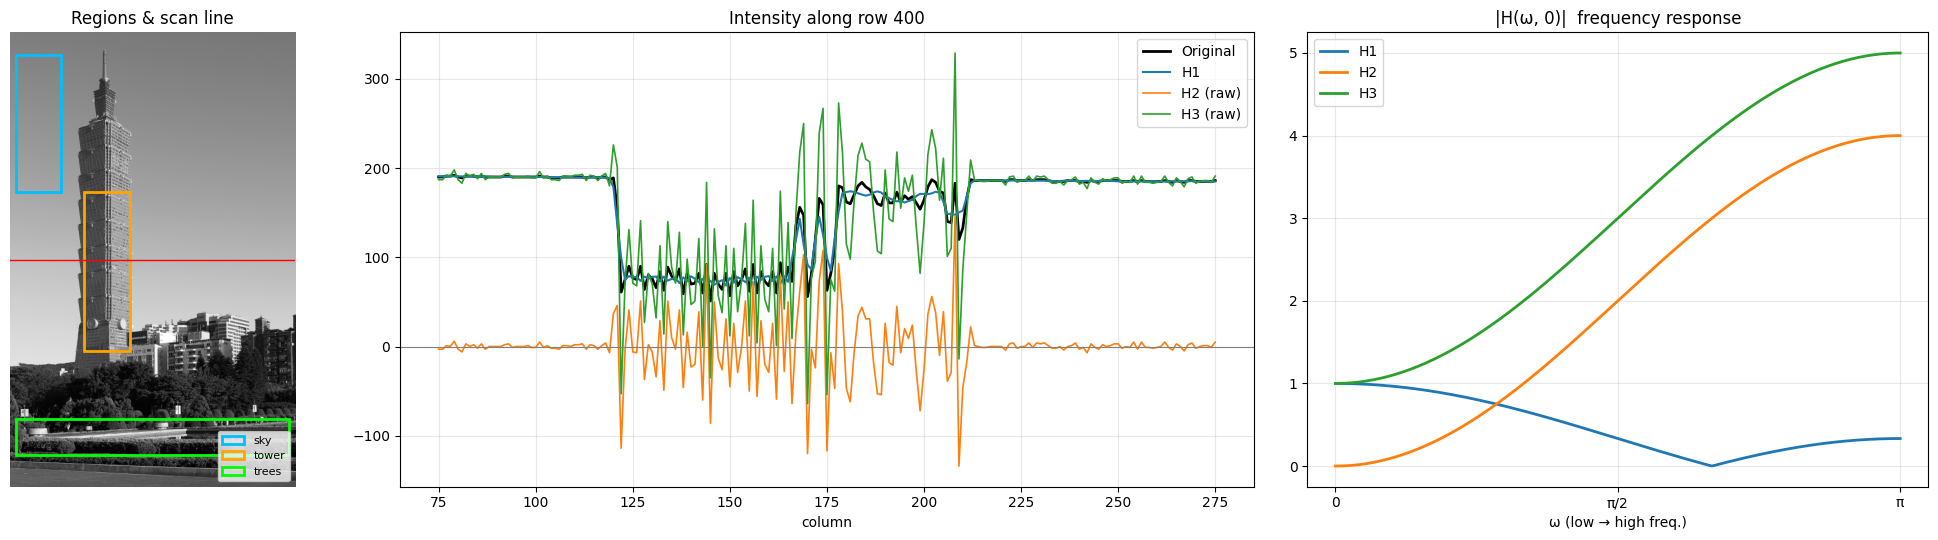

In [5]:
# 三-1 用數據判斷功能
REGIONS = {   # (列範圍, 行範圍)，以影像高寬的比例表示
    "sky":   (slice(int(0.05 * H_), int(0.35 * H_)), slice(int(0.02 * W_), int(0.18 * W_))),
    "tower": (slice(int(0.35 * H_), int(0.70 * H_)), slice(int(0.26 * W_), int(0.42 * W_))),
    "trees": (slice(int(0.85 * H_), int(0.93 * H_)), slice(int(0.02 * W_), int(0.98 * W_))),
}
colors = {"sky": "deepskyblue", "tower": "orange", "trees": "lime"}

import pandas as pd
rows = []
for rn, (rs, cs) in REGIONS.items():
    for stat, f in [("平均", np.mean), ("標準差", np.std)]:
        rows.append([rn, stat] + [round(float(f(a[rs, cs])), 2) for a in [gray, out1, out2, out3]])
display(pd.DataFrame(rows, columns=["區域", "統計量", "原圖", "H1", "H2", "H3"]).set_index(["區域", "統計量"]))
print(f"\n全圖平均：原圖 {gray.mean():.2f}｜H1 {out1.mean():.2f}｜H2 {out2.mean():.2f}｜H3 {out3.mean():.2f}")
print("檢查 H3 輸出 = 原圖 + H2 輸出：最大誤差 =", np.abs(out3 - (gray + out2)).max())

fig, axes = plt.subplots(1, 3, figsize=(20, 5.5), gridspec_kw={"width_ratios": [1, 2.2, 1.6]})
# (a) 區域位置
axes[0].imshow(gray, cmap="gray"); axes[0].set_title("Regions & scan line"); axes[0].axis("off")
for rn, (rs, cs) in REGIONS.items():
    axes[0].add_patch(plt.Rectangle((cs.start, rs.start), cs.stop - cs.start, rs.stop - rs.start,
                                    fill=False, ec=colors[rn], lw=2, label=rn))
row = int(0.50 * H_)
axes[0].axhline(row, color="red", lw=1); axes[0].legend(loc="lower right", fontsize=8)
# (b) 掃描線（只畫大樓附近一段）
c_a, c_b = int(0.15 * W_), int(0.55 * W_)
x = np.arange(c_a, c_b)
axes[1].plot(x, gray[row, c_a:c_b], "k", lw=2, label="Original")
axes[1].plot(x, out1[row, c_a:c_b], lw=1.5, label="H1")
axes[1].plot(x, out2[row, c_a:c_b], lw=1.2, label="H2 (raw)")
axes[1].plot(x, out3[row, c_a:c_b], lw=1.2, label="H3 (raw)")
axes[1].axhline(0, color="gray", lw=0.8)
axes[1].set_title(f"Intensity along row {row}"); axes[1].set_xlabel("column"); axes[1].legend(); axes[1].grid(alpha=0.3)
# (c) 頻率響應（水平方向）
om = np.linspace(0, np.pi, 300)
n = np.arange(-1, 2)
for name, Hk in KERNELS.items():
    resp = [abs(np.sum(Hk * np.exp(-1j * o * n)[None, :])) for o in om]
    axes[2].plot(om, resp, lw=2, label=name)
axes[2].set_xticks([0, np.pi / 2, np.pi]); axes[2].set_xticklabels(["0", "π/2", "π"])
axes[2].set_title("|H(ω, 0)|  frequency response"); axes[2].set_xlabel("ω (low → high freq.)")
axes[2].legend(); axes[2].grid(alpha=0.3)
plt.tight_layout(); plt.show()


### 判斷結果

| | H1 | H2 | H3 |
|:-:|---|---|---|
| **係數總和** | 1 | 0 | 1 |
| **輸出範圍** | 1.78～253，全在 0～255 內 | −466～579，45.7% 為負值 | −418～829，9.0% < 0、2.5% > 255 |
| **整體亮度（全圖平均）** | 123.43，與原圖 123.42 相同 | ≈ 0，亮度資訊消失 | 123.42，與原圖相同 |
| **天空（平滑區）標準差**<br>原圖 10.37 | 10.35（幾乎不變） | 2.63，輸出接近 0 | 10.84（幾乎不變） |
| **大樓（邊緣區）標準差**<br>原圖 50.27 | **45.31，下降約 10%** | 68.37，只剩變化量 | **100.30，約為原圖 2 倍** |
| **頻率響應** | ω=0 時為 1，高頻大幅衰減（ω=π 時僅 0.33）→ **低通** | ω=0 時為 0，ω=π 時最大（4）→ **高通** | ω=0 時為 1，ω=π 時放大到 5 → **低頻保留、高頻放大** |

**H1：平均濾波（低通／平滑、模糊）**
九個像素取平均，係數全正且總和為 1，所以平滑區和整體亮度不變，但窗格、樹葉等細節被抹平（大樓區標準差 50.27 → 45.31），並排圖（尤其局部放大）中的 H1 明顯較模糊。掃描線上，H1 曲線是原圖的平滑版本，劇烈起伏被削弱。適合**降雜訊**，代價是邊緣變模糊。

**H2：拉普拉斯濾波（高通／邊緣偵測）**
係數總和為 0：亮度均勻的地方輸出為 0（天空平均 0.00、標準差只剩 2.63），只有亮度突變處（大樓輪廓、窗格、樹葉）有大的正、負響應。所以圖中天空全黑、只剩線條。掃描線上，一個邊緣兩側會各出現一正一負的尖峰。適合**找出邊緣與細節**。

**H3：銳化濾波（原圖 + H2）**
H3 = H2 + 中心為 1 的單位脈衝，程式驗證「H3 輸出 = 原圖 + H2 輸出」誤差為 0。因此平滑區與整體亮度保持原樣，邊緣處則疊加 H2 的響應，對比被放大（大樓區標準差變為約 2 倍），圖中窗格與分節線更清楚。掃描線上，邊緣兩側出現超出原圖的過衝（overshoot）。適合**銳化影像**，代價是雜訊也一起被放大，且會產生超出 0～255 的值。

### 4　自訂應用：找出建築邊線

**應用目標：** 從照片中自動找出台北 101 的建築邊線（大樓外輪廓、每一節的分界與窗格線），可用於建築輪廓描繪，或作為後續直線偵測的前處理。

**選擇的 Kernel：H2。** 由上面的判斷，H2 的係數總和為 0，平滑的天空輸出約為 0，只有亮度突變處才有大的響應，取 |H2| 再設門檻就能得到邊線。
H1 與 H3 的係數總和為 1，輸出仍保留整張圖的亮度，天空和大樓一樣亮，無法只靠門檻分出邊線（下方 (1) 用數據比較）。

**作法：**
1. 三個 Kernel 都用同一規則「|輸出| > T」（T = 90）判斷邊線，比較各區域被標成邊線的比例。
2. 主要成果：|H2| > 90 的像素標為紅色，疊在原圖上。
3. 副作用檢查：在輸入加入 σ = 10 的雜訊（類似夜間或高 ISO 拍攝），看 H2 的結果。
4. 減輕副作用：先用 H1 平滑再用 H2（H1 → H2），門檻改為 25（平滑後響應變小）。

(1) 同一規則 |輸出| > 90 時，被標成邊線的像素比例（%）


,sky,tower,trees
H1,100.0,51.8,27.0
H2,0.0,14.4,18.6
H3,100.0,60.3,37.1



(2)~(4) 被標成邊線的像素比例（%）


,sky,tower,trees
H2，T=90（原圖）,0.0,14.4,18.6
H2，T=90（加入 σ=10 雜訊）,4.4,23.4,24.8
H1→H2，T=25（原圖）,0.0,10.9,12.8
H1→H2，T=25（加入 σ=10 雜訊）,0.0,13.1,14.6


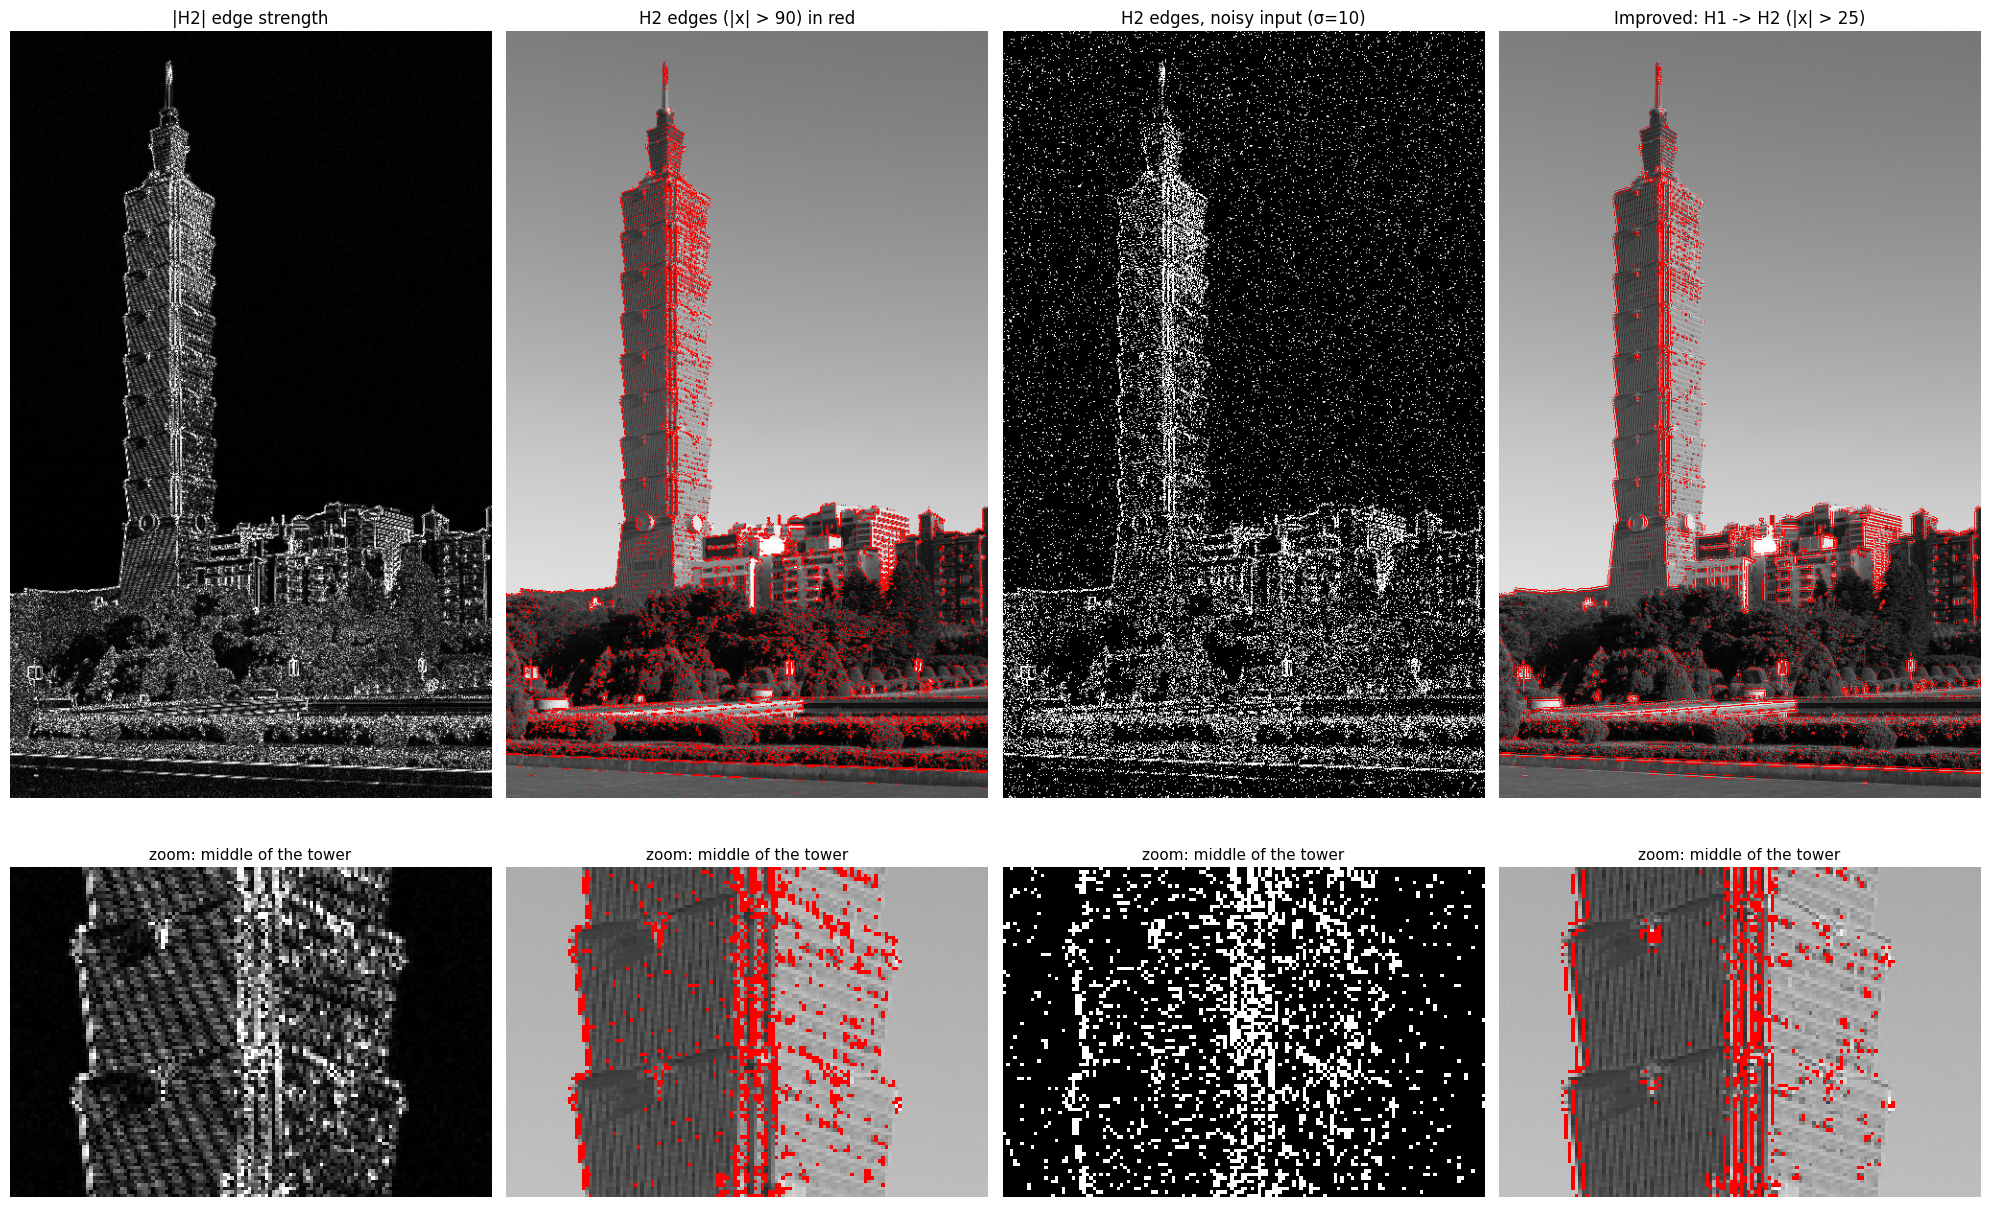

In [6]:
# 三-4 自訂應用：用 H2 找出建築邊線
import pandas as pd
T = 90   # 門檻：|H2 輸出| > T 視為邊線（約為 |H2| 前 7% 強的位置）

def edge_ratio(mask):
    return {rn: round(mask[rs, cs].mean() * 100, 1) for rn, (rs, cs) in REGIONS.items()}

def overlay_edges(mask):
    ov = np.stack([gray] * 3, axis=-1).astype(np.uint8)
    ov[mask] = [255, 0, 0]
    return ov

# (1) 為什麼選 H2：三個 Kernel 都用同一規則「|輸出| > T」
print(f"(1) 同一規則 |輸出| > {T} 時，被標成邊線的像素比例（%）")
display(pd.DataFrame({name: edge_ratio(np.abs(out) > T) for name, out in outs.items()}).T)

# (2) 主要成果：H2 邊線
edge = np.abs(out2) > T

# (3) 副作用檢查：輸入有雜訊時（σ=10，類似夜間或高 ISO 拍攝）
rng = np.random.default_rng(0)
gray_noisy = np.clip(gray + rng.normal(0, 10, gray.shape), 0, 255)
edge_noisy = np.abs(conv2d(gray_noisy, H2)) > T

# (4) 減輕副作用的方法：先用 H1 平滑，再用 H2（平滑後響應變小，門檻改為 25）
T_s = 25
edge_s       = np.abs(conv2d(conv2d(gray, H1), H2)) > T_s
edge_s_noisy = np.abs(conv2d(conv2d(gray_noisy, H1), H2)) > T_s

print("\n(2)~(4) 被標成邊線的像素比例（%）")
display(pd.DataFrame({
    f"H2，T={T}（原圖）":              edge_ratio(edge),
    f"H2，T={T}（加入 σ=10 雜訊）":     edge_ratio(edge_noisy),
    f"H1→H2，T={T_s}（原圖）":          edge_ratio(edge_s),
    f"H1→H2，T={T_s}（加入 σ=10 雜訊）": edge_ratio(edge_s_noisy),
}).T)

panels = [(show_abs_scaled(out2), "|H2| edge strength", "gray"),
          (overlay_edges(edge), f"H2 edges (|x| > {T}) in red", None),
          (edge_noisy, f"H2 edges, noisy input (σ=10)", "gray"),
          (overlay_edges(edge_s), f"Improved: H1 -> H2 (|x| > {T_s})", None)]
fig, axes = plt.subplots(2, 4, figsize=(20, 13), gridspec_kw={"height_ratios": [3, 1.2]})
for k, (im, t, cm) in enumerate(panels):
    axes[0, k].imshow(im, cmap=cm); axes[0, k].set_title(t, fontsize=12)
    axes[1, k].imshow(im[zoom], cmap=cm, interpolation="nearest"); axes[1, k].set_title("zoom: middle of the tower", fontsize=11)
    for ax in axes[:, k]: ax.axis("off")
plt.tight_layout(); plt.show()


### 結果與討論

**1. H2 是最適合的 Kernel**
同一規則 |輸出| > 90 時，H1 與 H3 會把**天空 100% 標成邊線**（因為天空本身亮度約 147 > 90），只是在做亮度門檻，不是在找邊線；H2 的天空為 **0%**，被標出的像素集中在大樓（14.4%）與樹叢（18.6%）。

**2. 是否達到目的：大致達到**
紅色疊圖中，台北 101 的外輪廓、每一節的分界與窗格線都被標出，背景天空完全乾淨；|H2| 邊緣強度圖也清楚呈現建築的線條結構。

**3. 可能的副作用**
- **無法區分「建築邊線」與「雜亂紋理」**：H2 對所有亮度突變都有反應，樹叢被標成邊線的比例（18.6%）甚至高於大樓（14.4%），窗格的細紋也和大樓外輪廓一樣被標出。若只要大樓輪廓，還需要另外篩選（例如再找直線）。
- **對雜訊很敏感**：H2 是高通濾波，最高頻放大 4 倍，雜訊被放大後超過門檻。加入 σ = 10 的雜訊後，天空的誤判由 0% 升到 **4.4%**，大樓由 14.4% 升到 23.4%，第三張圖中天空出現大量白點。
- **邊線變粗、成雙**：拉普拉斯在一個邊緣的兩側各產生一正一負的響應（見掃描線圖），取 |x| 後一條邊會變成約兩個像素寬的雙線。
- **門檻要人工決定**：T 太小會把整片窗格與樹葉都標成邊線，T 太大則邊線斷斷續續；不同照片要重新調整。

**4. 減輕方法：先 H1 再 H2**
先用 H1 抑制雜訊與細紋，再用 H2 找邊線。有雜訊時天空的誤判由 4.4% 降回 **0.0%**，樹叢由 24.8% 降到 14.6%；第四張圖中大樓外輪廓與分節線更連續，窗格細紋明顯減少。
代價是最細的窗格線也一起被平滑掉，邊線位置稍微變寬，這是 H1 模糊作用的副作用，屬於「降雜訊」與「保留細節」之間的取捨。